# 00 . Brainnetome 246 to Schaefer100 mapping

MEG-Mamba takes Schaefer100 parcellated input at 250 Hz. We are on Brainnetome 210, so
this builds the mapping, the same spatial-overlap method as `notebooks_parcel/10`.

**Prerequisite.** The atlas file `atlas-Schaefer_nparc-100_space-MNI_res-8x8x8.nii.gz`
is not bundled with osl-dynamics, it is served at runtime. Get it from
[osl-files/docs/parcellations](https://github.com/OHBA-analysis/osl-files/tree/main/docs/parcellations)
or ask Sid, and put it in `data/schaefer100/`.

**Known caveat.** MEG-Mamba's tokeniser was trained on recordings beamformed directly to
Schaefer100. Remapping someone else's Brainnetome reconstruction is not the same operation,
so the tokens may not look like what the model expects. Notebook 01 checks that before
anything expensive runs.

In [2]:
import os, sys
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np, nibabel as nib
import matplotlib.pyplot as plt

DATA    = '../data'
BN      = f'{DATA}/brainnetome_atlas/BN_Atlas_246_2mm.nii.gz'
# Shipped inside the osl-ephys package. The 2 mm label volume is used rather than the
# 8 mm one MEG-Mamba names, because finer voxels give more precise overlap counts and
# the parcel definitions are identical.
SCHAEFER = f'{DATA}/schaefer100/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
OUT     = '../results_mamba'
PARCEL  = '../results_parcel'      # reuse ids and keep_idx from the Brainnetome work
SUFFIX  = 'schaefer100'
os.makedirs(OUT, exist_ok=True)

assert os.path.exists(SCHAEFER), (
    'Schaefer100 atlas missing. Extract it from the osl-ephys package:\n'
    '  pip download osl-ephys --no-deps -d /tmp/oe\n'
    '  then pull osl_ephys/source_recon/parcellation/files/Schaefer2018_100Parcels_*\n'
    '  into data/schaefer100/')

bn = nib.load(BN);       B = bn.get_fdata()
sc = nib.load(SCHAEFER); S_ = sc.get_fdata()
print(f'brainnetome {B.shape} at {np.round(bn.header.get_zooms()[:3],1)} mm')
print(f'schaefer100 {S_.shape} at {np.round(sc.header.get_zooms()[:3],1)} mm')

# Schaefer may ship as a 3D label volume (like Brainnetome) or a 4D mask stack
# (like Glasser52). Normalise to a label volume either way.
if S_.ndim == 4:
    assert (S_.sum(axis=3) > 1).sum() == 0, 'parcels overlap'
    Slab = np.zeros(S_.shape[:3], int)
    for k in range(S_.shape[3]):
        Slab[S_[..., k] > 0] = k + 1
else:
    Slab = S_.astype(int)
N_PARCELS = int(Slab.max())
print(f'label volume with {N_PARCELS} parcels, {(Slab>0).sum()} voxels')
assert N_PARCELS == 100, f'expected 100 parcels, got {N_PARCELS}'

brainnetome (91, 109, 91) at [2. 2. 2.] mm
schaefer100 (91, 109, 91) at [2. 2. 2.] mm
label volume with 100 parcels, 132032 voxels


In [3]:
# Same construction as notebooks_parcel/10. For each Brainnetome region, count how many
# of its voxels land in each Schaefer parcel, going through world coordinates since the
# two atlases sit on different grids.
ids = np.load(f'{PARCEL}/parcel_ids_cortical.npy')
print(f'{len(ids)} brainnetome regions, in Pooja row order')

inv_sc = np.linalg.inv(sc.affine)
W = np.zeros((len(ids), N_PARCELS))
region_voxels = np.zeros(len(ids), int)

for r, rid in enumerate(ids):
    vox = np.argwhere(B == rid)
    region_voxels[r] = len(vox)
    mni = nib.affines.apply_affine(bn.affine, vox)
    si  = np.rint(nib.affines.apply_affine(inv_sc, mni)).astype(int)
    ok  = np.all((si >= 0) & (si < np.array(Slab.shape)), axis=1)
    lab = Slab[si[ok, 0], si[ok, 1], si[ok, 2]]
    for p in range(1, N_PARCELS + 1):
        W[r, p - 1] = (lab == p).sum()

np.save(f'{OUT}/schaefer_W_counts.npy', W)
print(f'weight matrix {W.shape}')
print(f'regions mapping to no parcel : {int((W.sum(1) == 0).sum())}')
print(f'parcels receiving no region  : {int((W.sum(0) == 0).sum())}')
print(f'median fraction of a region landing in some parcel: {np.median(W.sum(1)/region_voxels):.3f}')
print(f'regions per parcel: min {int((W>0).sum(0).min())}  max {int((W>0).sum(0).max())}')

210 brainnetome regions, in Pooja row order
weight matrix (210, 100)
regions mapping to no parcel : 0
parcels receiving no region  : 0
median fraction of a region landing in some parcel: 0.934
regions per parcel: min 3  max 17


## Merge method

Same PCA merge as the Glasser52 work, for the same reason. Pooja's regions carry arbitrary
signs, so averaging cancels signal. PC1 is invariant to those signs.

Note that MEG-Mamba's README says no sign flipping is needed for *their* pipeline, because
their beamformer output does not have the problem. Ours does, which is why this step stays.

In [4]:
def pca_merge(sig, W):
    """(210, T) regions -> (n_parcels, T) via each parcel's first principal component."""
    out = np.zeros((W.shape[1], sig.shape[1]), np.float32)
    for p in range(W.shape[1]):
        m = np.where(W[:, p] > 0)[0]
        if len(m) == 0:
            continue
        X = sig[m] - sig[m].mean(1, keepdims=True)
        X = X / (X.std(1, keepdims=True) + 1e-12)
        U, Sv, Vt = np.linalg.svd(X, full_matrices=False)
        comp = Vt[0] * Sv[0]
        if np.corrcoef(comp, X.mean(0))[0, 1] < 0:
            comp = -comp
        out[p] = comp
    return out

print('pca_merge ready')

pca_merge ready


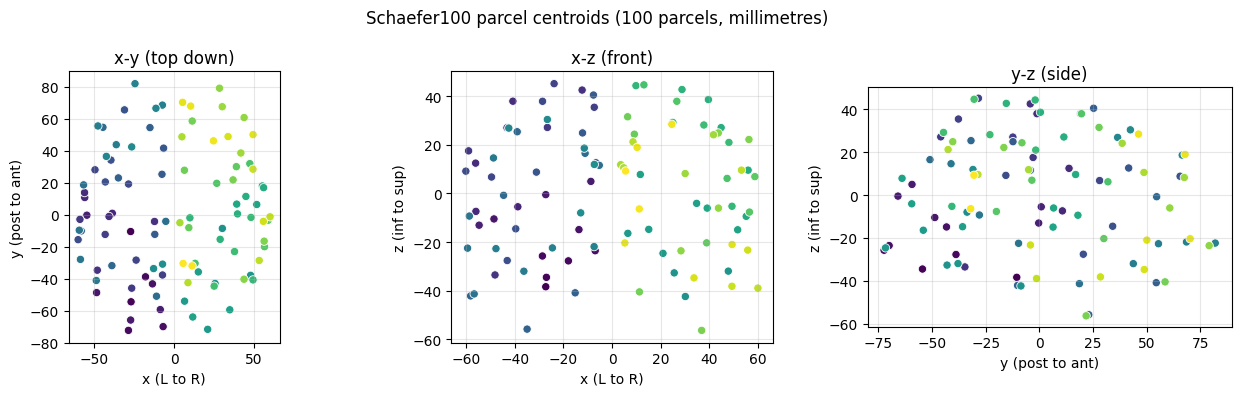

next: notebook 01, feasibility check on the tokeniser


In [5]:
# Sanity: centroids should trace a brain. Geometry is not needed by MEG-Mamba, which uses
# learned per-parcel embeddings rather than positions, but it is a free check that the
# mapping landed in the right place.
cent = np.zeros((N_PARCELS, 3))
for p in range(1, N_PARCELS + 1):
    vox = np.argwhere(Slab == p)
    cent[p-1] = nib.affines.apply_affine(sc.affine, vox.mean(axis=0))
pos = cent - cent.mean(0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
views = [('x-y (top down)', 0, 1, 'x (L to R)', 'y (post to ant)'),
         ('x-z (front)',    0, 2, 'x (L to R)', 'z (inf to sup)'),
         ('y-z (side)',     1, 2, 'y (post to ant)', 'z (inf to sup)')]
for ax, (title, a, b_, xl, yl) in zip(axes, views):
    ax.scatter(pos[:, a], pos[:, b_], s=36, c=np.arange(N_PARCELS), cmap='viridis',
               edgecolor='white', linewidth=.6)
    ax.set_title(title); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.suptitle(f'Schaefer100 parcel centroids ({N_PARCELS} parcels, millimetres)')
plt.tight_layout(); plt.savefig(f'{OUT}/schaefer100_geometry_check.png', dpi=150); plt.show()
print('next: notebook 01, feasibility check on the tokeniser')